<table style="width:100%; border:none"><tr style="border:none"><td style="text-align:left; border:none">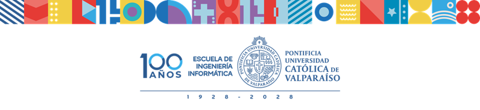</td><td style="text-align:right; border:none">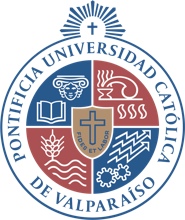</td></tr></table>


# Taller introductorio: ver la meseta y reaccionar

**Lucas Erazo**  
Escuela de Ingeniería Informática  
Pontificia Universidad Católica de Valparaíso

Una metaheurística guarda el mejor valor que encontró hasta el momento. Esa curva sube al principio y después se aplana. En este taller armas un monitor que detecta cuándo la curva se aplanó, y ves cómo reacciona la búsqueda: cambia sus parámetros.

Trabajamos con dos problemas: la mochila multidimensional (MKP) y HRES2, el diseño de un sistema de viento, solar, batería y electrolizador.

Esta es la versión resuelta: `calcular_D1_D2_delta` ya está escrita y todas las celdas están ejecutadas.

| # | Sección | Qué haces |
|---|---|---|
| 1 | La curva y la meseta | Miras una corrida y estimas dónde se estanca. |
| 2 | Rampa o constante | Lees la función ya escrita. |
| 3 | Cuándo dispara | Ves dónde marca el monitor. |
| 4 | Jugar con las perillas | Cambias `W`, `band` y `patience`. |
| 5 | Reaccionar con parámetros | Comparas la búsqueda con y sin reacción. |
| 6 | HRES2: el mismo monitor en otro problema | Pruebas tu propio sistema de energía y corres GWO-DE con el monitor. |
| 7 | Cierre | Comentan tres preguntas en grupo. |

**Antes de empezar:** en Colab, abre *Entorno de ejecución → Ejecutar todas*.

**Celdas ocultas:** las celdas con mucho código aparecen solo con su título. Haz doble clic en el título para ver el código.

**Para quien guía el taller:** las secciones 4 y 5 son el centro del taller: no las recortes.


## 1. La curva y la meseta

El problema de la mochila multidimensional (MKP): eliges ítems para **maximizar la ganancia** total, sin pasar ninguno de los **límites de capacidad**. Cada ítem entra o no entra.

Una búsqueda prueba soluciones y guarda la mejor hasta ahora. Esa curva sube al principio y después se aplana: eso es una **meseta**.

Las celdas siguientes cargan la instancia y la búsqueda (GWO, *Grey Wolf Optimizer*). Puedes ejecutarlas sin leerlas en detalle.


In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import requests
from dataclasses import dataclass, replace

SEMILLA = 0          # semilla para las corridas
plt.rcParams.update({"figure.figsize": (8, 3.4), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__)


numpy 2.4.4


Descargamos `mknapcb1` de OR-Library: 30 instancias de 100 ítems y 5 restricciones. Si la descarga falla, se genera una instancia de respaldo del mismo tamaño. Esa instancia no trae mejor valor conocido.


In [2]:
#@title Descargar la instancia del MKP { display-mode: "form" }
ARCHIVO = "mknapcb1.txt"
URLS = [f"https://people.brunel.ac.uk/~mastjjb/jeb/orlib/files/{ARCHIVO}",
        f"http://people.brunel.ac.uk/~mastjjb/jeb/orlib/files/{ARCHIVO}"]

text_content, INSTANCIA_GENERADA = None, False
for url in URLS:
    try:
        resp = requests.get(url, timeout=20)
        resp.raise_for_status()
        text_content = resp.text
        print("Instancia descargada desde", url)
        break
    except requests.exceptions.RequestException as e:
        print(f"No se pudo descargar {url}: {e}")

if text_content is None:
    # Respaldo: instancia GENERADA al estilo Chu y Beasley (no es de OR-Library).
    INSTANCIA_GENERADA = True
    g = np.random.default_rng(12345)
    n_g, m_g, alfa = 100, 5, 0.25
    r_g = g.integers(0, 1001, size=(m_g, n_g))
    b_g = np.floor(alfa * r_g.sum(axis=1))
    p_g = np.floor(r_g.sum(axis=0) / m_g + 500 * g.random(n_g))
    lineas = ["1", f"{n_g} {m_g} 0", " ".join(map(str, p_g.astype(int)))]
    lineas += [" ".join(map(str, fila)) for fila in r_g]
    lineas += [" ".join(map(str, b_g.astype(int)))]
    text_content = "\n".join(lineas)
    print("ATENCIÓN: se usa una instancia GENERADA (n=100, m=5), sin mejor conocido.")


Instancia descargada desde https://people.brunel.ac.uk/~mastjjb/jeb/orlib/files/mknapcb1.txt


In [3]:
#@title Leer las instancias (código del curso) { display-mode: "form" }
def cargar_instancia_mkp(cadena):
  # Lista de instancias del problema
  instancias = []

  # Dividir la cadena en líneas y luego en números
  lineas = cadena.strip().split('\n')
  numeros = [list(map(float, linea.split())) for linea in lineas]

  #Lector de archivo
  linea_actual = 0

  # Extraer la cantidad de instancias que contiene el archivo
  n_instancias = int(numeros[linea_actual][0])

  for _ in range(n_instancias):

    # Esto es para que se salte la linea vacía que hay entre instancias
    linea_actual += 1
    if numeros[linea_actual] == [] :
      linea_actual += 1

    # Extraer n, m, y el valor de la solución óptima
    n, m, valor_optimo = numeros[linea_actual]
    n, m = [int(n), int(m)]

    linea_actual += 1

    p = []

    while (len(p)<n):
      p += numeros[linea_actual]
      linea_actual += 1

    # Inicializar una lista vacía para las restricciones y los lados derechos
    r = []
    b = []

    # Extraer los coeficientes de las restricciones r(i,j) y b(i)
    for i in range(m):
      new_restriction = []
      while(len(new_restriction) < n):
        new_restriction = new_restriction + numeros[linea_actual]
        linea_actual += 1
      r.append(new_restriction)  # Agregar la nueva lista a r

    while (len(b) < m):
      b += numeros[linea_actual]
      linea_actual += 1
    linea_actual -= 1

    p = np.array(p)
    r = np.array(r)
    b = np.array(b)

    instancias.append({"n": n, "m": m, "valor_optimo": valor_optimo, "p": p, "r": r, "b": b})

  return instancias

instancias = cargar_instancia_mkp(text_content)

INDICE_INSTANCIA = 9
# Mejor conocido para mknapcb1 (problemas 5.100-00 a 5.100-09), copiado de OR-Library mkcbres.txt
MEJOR_CONOCIDO_CB1 = {0: 24381, 1: 24274, 2: 23551, 3: 23534, 4: 23991,
                      5: 24613, 6: 25591, 7: 23410, 8: 24216, 9: 24411}

if INSTANCIA_GENERADA:
    data = instancias[0]
    mejor_conocido = None
else:
    data = instancias[INDICE_INSTANCIA]
    mejor_conocido = MEJOR_CONOCIDO_CB1.get(INDICE_INSTANCIA)

n, m = data['n'], data['m']
p, r, b = data['p'], data['r'], data['b']
print(f"n={n}, m={m}, mejor conocido={mejor_conocido}")


n=100, m=5, mejor conocido=24411


In [4]:
#@title Reparar soluciones infactibles { display-mode: "form" }
# Reparación (estilo LB2): saca ítems por densidad ascendente hasta que la solución sea factible y luego intenta agregar.
density_per_bag = [p / r[i] for i in range(m)]
density_per_bag = np.array(density_per_bag)

# Encontrar el valor máximo entre los elementos finitos
finite_max = np.max(density_per_bag[np.isfinite(density_per_bag)])
# Reemplazar los valores infinitos con el valor máximo encontrado * 10
density_per_bag[np.isinf(density_per_bag)] = finite_max * 10

density = np.min(density_per_bag, axis=0)
# Obtener los índices en orden ascendente
indices_ascendentes = np.argsort(density)

# Función de reparación modificada para usar índices y orden precalculados
def reparar_solucion(solucion, p, r, b, density):
  for i in range(len(solucion)):
    aux = solucion.copy()
    aux[int(indices_ascendentes[i])] = 0
    if not np.all(np.dot(aux, r.T) <= b):
      solucion = aux
    else:
      solucion = aux
      break

  for i in range(len(solucion)):
    aux = solucion.copy()
    aux[int(indices_ascendentes[i])] = 1
    if np.all(np.dot(aux, r.T) <= b):
      solucion = aux
    else:
      break

  valor_total = np.sum(solucion * p)
  return solucion, valor_total


In [5]:
#@title GWO y binarización LB2 { display-mode: "form" }
# Tamaño de población e iteraciones
num_individuos = 20
num_iteraciones = 1000

# Parámetros de binarización LB2 (los del notebook del curso)
V_max = 8
G1_i, G1_f = 0.5, 1
G2_i, G2_f = 0.5, 0.9*V_max
G3_i, G3_f = 0.5, 0

EVALUACIONES = num_individuos + num_iteraciones * num_individuos * 2   # 2 reparaciones LB2 por individuo e iteración

def gwo_candidato(x, lideres, a, rng):
    # Un candidato GWO: promedio de las tres posiciones guiadas por alfa, beta y delta, recortado a [-V_max, V_max].
    n_ = x.shape[0]
    guiados = np.empty((3, n_))
    for k in range(3):
        A = 2.0 * a * rng.random(n_) - a
        C = 2.0 * rng.random(n_)
        D = np.abs(C * lideres[k] - x)
        guiados[k] = lideres[k] - A * D
    return np.clip(guiados.mean(axis=0), -V_max, V_max)

def lb2_binarizar(v, actual, rng, G1, G2, G3):
    denom = V_max - G2
    if abs(denom) < 1e-12:
        denom = 1e-12
    L1 = np.clip(-G1 * v / denom + G3, 0.0, 1.0)
    L2 = np.clip( G1 * v / denom + G3, 0.0, 1.0)
    actual = np.asarray(actual, dtype=int)
    x1 = np.where(rng.random(n) < L1, 1 - actual, actual)
    x2 = np.where(rng.random(n) < L2, 1 - actual, actual)
    x1, val_1 = reparar_solucion(x1, p, r, b, indices_ascendentes)
    x2, val_2 = reparar_solucion(x2, p, r, b, indices_ascendentes)
    if val_1 > val_2:
        return x1, val_1
    return x2, val_2

def mh_mkp(semilla, num_iteraciones=num_iteraciones):
    # GWO solo. Devuelve el mejor acumulado en cada iteración.
    rng = np.random.default_rng(semilla)
    x_real = rng.uniform(-V_max, V_max, (num_individuos, n))
    x_bin = np.zeros((num_individuos, n), dtype=int)
    fit = np.empty(num_individuos)
    mejor_valor = -np.inf
    for i in range(num_individuos):
        x_bin[i], fit[i] = reparar_solucion((x_real[i] > 0).astype(int), p, r, b, indices_ascendentes)
        if fit[i] > mejor_valor:
            mejor_valor = fit[i]

    historial = []
    for iteracion in range(num_iteraciones):
        G1 = G1_f + (G1_i - G1_f)/(1 - num_iteraciones)*(iteracion - num_iteraciones)
        G2 = G2_f + (G2_i - G2_f)/(1 - num_iteraciones)*(iteracion - num_iteraciones)
        G3 = G3_f + (G3_i - G3_f)/(1 - num_iteraciones)*(iteracion - num_iteraciones)
        a = 2.0 * (1.0 - iteracion / num_iteraciones)
        orden = np.argsort(fit)[::-1]
        lideres = x_real[orden[:3]].copy()   # se congelan para toda la generación
        for i in range(num_individuos):
            u = gwo_candidato(x_real[i], lideres, a, rng)
            bits, val = lb2_binarizar(u, x_bin[i], rng, G1, G2, G3)
            if val >= fit[i]:
                x_real[i], x_bin[i], fit[i] = u, bits, val
                if val > mejor_valor:
                    mejor_valor = val
        historial.append(float(mejor_valor))
    return np.array(historial)


GWO, semilla 0: mejor = 22911  (24.2 s)


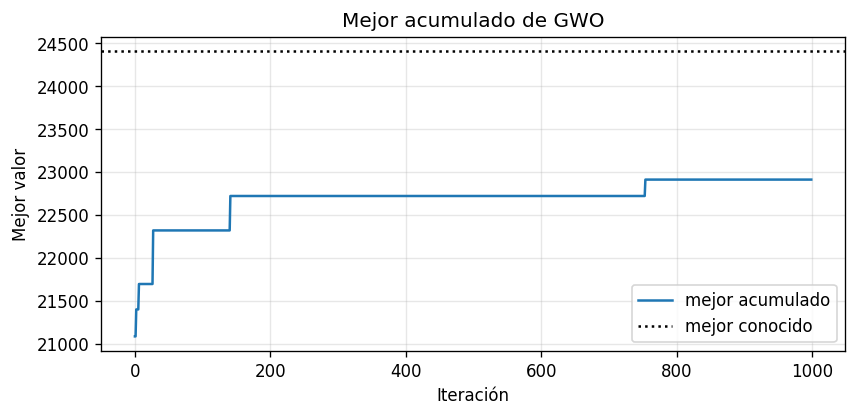

In [6]:
t0 = time.time()
hist_gwo = mh_mkp(SEMILLA)
print(f"GWO, semilla {SEMILLA}: mejor = {hist_gwo[-1]:.0f}  ({time.time()-t0:.1f} s)")

def graficar_convergencia(hist, titulo, marcas=None, etiqueta_marcas="marca"):
    plt.plot(hist, label="mejor acumulado")
    if mejor_conocido:
        plt.axhline(mejor_conocido, color="k", ls=":", label="mejor conocido")
    for k, x in enumerate(marcas or []):
        plt.axvline(x, color="tab:red", ls="--", alpha=0.7, label=etiqueta_marcas if k == 0 else None)
    plt.xlabel("Iteración"); plt.ylabel("Mejor valor"); plt.title(titulo); plt.legend(); plt.show()

graficar_convergencia(hist_gwo, "Mejor acumulado de GWO")


**Tu turno:** mira el gráfico. ¿Desde qué iteración dirías que la búsqueda se estancó? Anótalo en `mi_estimacion` y compáralo con tu compañero. No hay una respuesta correcta: más adelante la comparas con lo que marca el monitor.


In [7]:
mi_estimacion = None      # p. ej. 120

if mi_estimacion is not None:
    graficar_convergencia(hist_gwo, "Tu estimación", [mi_estimacion], "mi estimación")


## 2. Rampa o constante

El monitor mira los últimos $W$ puntos de la curva. Los compara con dos referencias que parten en el primer punto $x_0$ de la ventana:

- una **rampa** $x_0 + s\,k$, que sube $s$ por paso (la curva sigue mejorando),
- una **constante** $x_0$ (la curva está plana).

Con esas dos comparaciones calcula tres números:

- $D_1$ = distancia de la ventana a la rampa,
- $D_2$ = distancia de la ventana a la constante,
- $\Delta = D_1 - D_2$.

**$\Delta$ positivo: la ventana está más cerca de la meseta.** $\Delta$ negativo: más cerca de la rampa.

La distancia es DTW (*Dynamic Time Warping*): mide qué tan distintas son dos series y permite un pequeño corrimiento en el tiempo. La función ya viene escrita.


In [8]:
def dtw_distance(s, t, band=None):
    s = np.asarray(s, dtype=float); t = np.asarray(t, dtype=float)
    n_s, n_t = len(s), len(t)
    if band is None:
        band = max(n_s, n_t)
    band = max(band, abs(n_s - n_t))          # la banda debe permitir llegar a (n, m)
    D = np.full((n_s + 1, n_t + 1), np.inf)
    D[0, 0] = 0.0
    for i in range(1, n_s + 1):
        for j in range(max(1, i - band), min(n_t, i + band) + 1):
            costo = abs(s[i-1] - t[j-1])
            D[i, j] = costo + min(D[i-1, j], D[i, j-1], D[i-1, j-1])
    return float(D[n_s, n_t])

# Misma forma con un paso repetido: DTW da 0.
print("dtw([1,2,3], [1,2,2,3]) =", dtw_distance([1, 2, 3], [1, 2, 2, 3]))
assert dtw_distance([1, 2, 3], [1, 2, 2, 3]) == 0


dtw([1,2,3], [1,2,2,3]) = 0.0


Esta celda define la configuración del monitor y dos funciones que vas a usar: `pendiente_rampa(X, cfg)` entrega la pendiente $s$ y `distancia(a, b, cfg)` calcula DTW con la banda de la configuración.


In [9]:
#@title Configuración del monitor y funciones de apoyo { display-mode: "form" }
@dataclass
class ConfigMonitor:
    W: int = 40               # largo de la ventana
    band: int = 4             # banda Sakoe-Chiba (10 % de W)
    plateau_max: int = 15     # iteraciones sin mejora exigidas
    patience: int = 8         # observaciones seguidas exigidas
    min_slope: float = 2.0    # unidades de fitness por iteración (fija; 0 -> pendiente automática del código original)
    p_low: float = 40.0       # percentil para theta_c
    p_high: float = 60.0      # percentil para theta_r y theta_delta
    adaptativo: bool = True

CFG_DEFECTO = ConfigMonitor()

def distancia(s, t, cfg):
    # DTW con la banda de la configuración
    return dtw_distance(s, t, band=cfg.band)

def pendiente_rampa(X, cfg):
    if cfg.min_slope != 0.0:
        return cfg.min_slope
    return 0.01 * max(1.0, abs(X[-1] - X[0])) / len(X)


In [10]:
def calcular_D1_D2_delta(X, cfg):
    X = np.asarray(X, dtype=float)
    W, x0 = len(X), X[0]
    s = pendiente_rampa(X, cfg)
    rampa = x0 + s * np.arange(W)
    constante = np.full(W, x0)
    D1 = distancia(X, rampa, cfg)
    D2 = distancia(X, constante, cfg)
    delta = D1 - D2
    return D1, D2, delta


**Comprobación** con dos ventanas sintéticas (debe terminar sin `AssertionError`):


In [11]:
plana  = np.full(40, 100.0)
subida = 100.0 + 10.0 * np.arange(40)
for nombre, X in [("plana", plana), ("subida", subida)]:
    D1, D2, dl = calcular_D1_D2_delta(X, CFG_DEFECTO)
    print(f"{nombre:7s}: D1={D1:9.2f}  D2={D2:9.2f}  Δ={dl:9.2f}  ({'+ más cerca de meseta' if dl > 0 else '− más cerca de rampa'})")
D1, D2, dl = calcular_D1_D2_delta(plana, CFG_DEFECTO)
assert D2 == 0 and D1 > 0 and dl > 0
D1, D2, dl = calcular_D1_D2_delta(subida, CFG_DEFECTO)
assert D2 > D1 and dl < 0
print("Todo OK ✅")


plana  : D1=  1560.00  D2=     0.00  Δ=  1560.00  (+ más cerca de meseta)
subida : D1=  5960.00  D2=  7800.00  Δ= -1840.00  (− más cerca de rampa)
Todo OK ✅


## 3. Cuándo dispara

El monitor recibe un punto nuevo de la curva en cada iteración. **Dispara** cuando se cumplen las tres condiciones durante `patience` observaciones seguidas:

1. La curva lleva `plateau_max` pasos sin mejorar.
2. La ventana se parece a la constante: $D_2 \le \theta_c$.
3. La ventana no se parece a la rampa: $D_1 \ge \theta_r$ o $\Delta \ge \theta_\Delta$.

Los umbrales salen de la historia del propio monitor. Con 10 observaciones o más, $\theta_c$ es el percentil 40 de los $D_2$ anteriores, y $\theta_r$ y $\theta_\Delta$ son el percentil 60 de los $D_1$ y $\Delta$ anteriores. Con menos de 10 se usan valores fijos: $0.1W$, $0.5W$ y $0.3W$.

Después de disparar, el monitor parte de cero: ventana, contadores e historial de umbrales.

**Tu turno:** en el gráfico, compara las líneas rojas con la iteración que anotaste en `mi_estimacion`.


Detecciones (iteración): [73, 120, 187, 234, 281, 328, 375, 422, 469, 516, 563, 610, 657, 704, 751, 800, 847, 894, 941, 988] | tu estimación: None


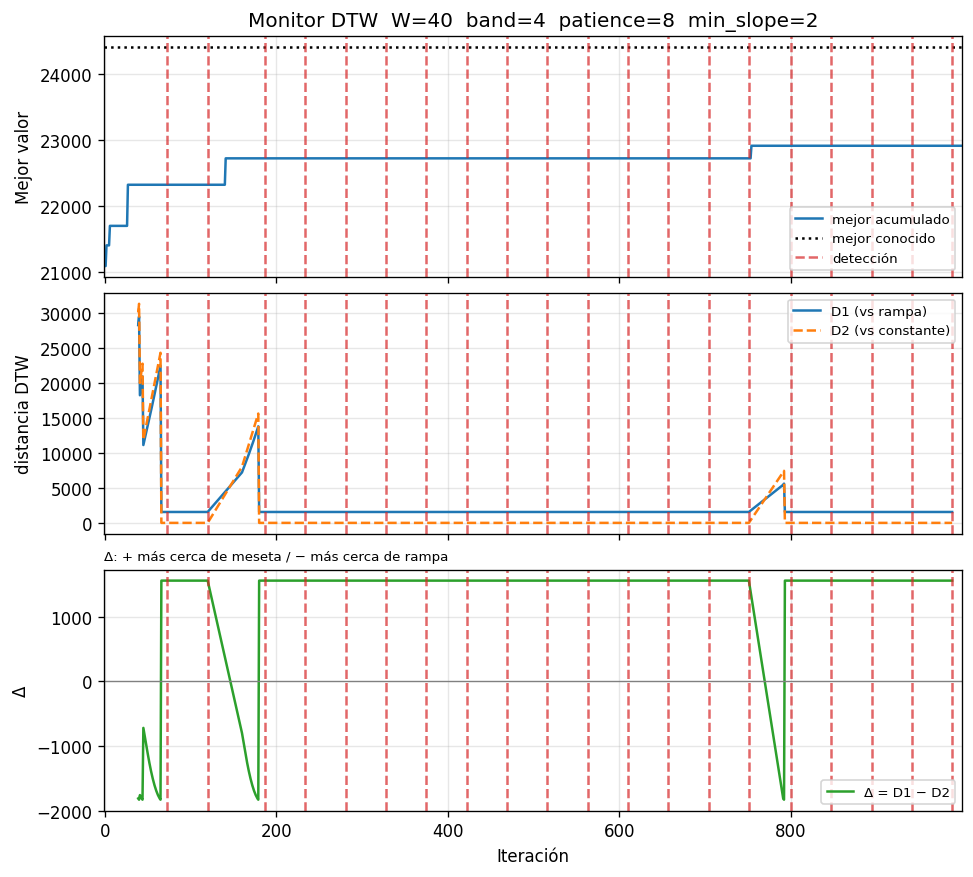

In [12]:
#@title Monitor DTW y gráfico de detecciones { display-mode: "form" }
class MonitorDTW:
    def __init__(self, cfg=CFG_DEFECTO):
        self.cfg = cfg
        self.serie, self.sin_mejora, self.racha = [], 0, 0
        self.h_D1, self.h_D2, self.h_delta = [], [], []

    def reiniciar_ventana(self):
        # monitor nuevo tras una reacción: ventana, contadores e historias de umbrales en cero
        # (igual que gwo_de_dtw/controller.py, que reemplaza el monitor completo)
        self.serie, self.sin_mejora, self.racha = [], 0, 0
        self.h_D1, self.h_D2, self.h_delta = [], [], []

    def update(self, mejor):
        mejor = float(mejor)
        if self.serie and mejor <= self.serie[-1]:
            self.sin_mejora += 1; mejor = self.serie[-1]
        else:
            self.sin_mejora = 0
        self.serie.append(mejor)
        W = self.cfg.W
        if len(self.serie) < W:
            return {"listo": False, "disparo": False, "sin_mejora": self.sin_mejora}
        X = np.array(self.serie[-W:])
        D1, D2, delta = calcular_D1_D2_delta(X, self.cfg)
        self.h_D1.append(D1); self.h_D2.append(D2); self.h_delta.append(delta)
        if self.cfg.adaptativo and len(self.h_D1) >= 10:
            th_c = np.percentile(self.h_D2, self.cfg.p_low)
            th_r = np.percentile(self.h_D1, self.cfg.p_high)
            th_d = np.percentile(self.h_delta, self.cfg.p_high)
        else:
            th_c, th_r, th_d = 0.1 * W, 0.5 * W, 0.3 * W
        c_meseta = self.sin_mejora >= self.cfg.plateau_max
        c_const  = D2 <= th_c
        c_rampa  = (D1 >= th_r) or (delta >= th_d)
        self.racha = self.racha + 1 if (c_meseta and c_const and c_rampa) else 0
        return {"listo": True, "disparo": self.racha >= self.cfg.patience,
                "D1": D1, "D2": D2, "delta": delta, "theta_c": th_c, "theta_r": th_r, "theta_delta": th_d,
                "sin_mejora": self.sin_mejora}

def analizar(hist, cfg=CFG_DEFECTO):
    # Pasa el monitor sobre una serie ya corrida (sin reaccionar). Tras cada detección
    # reinicia el monitor, igual que hará la reacción de la sección 5.
    mon = MonitorDTW(cfg)
    D1 = np.full(len(hist), np.nan); D2 = D1.copy(); dl = D1.copy(); detecciones = []
    for it, v in enumerate(hist):
        o = mon.update(v)
        if o["listo"]:
            D1[it], D2[it], dl[it] = o["D1"], o["D2"], o["delta"]
        if o["disparo"]:
            detecciones.append(it); mon.reiniciar_ventana()
    return D1, D2, dl, detecciones

def graficar_monitor(hist, cfg=CFG_DEFECTO, titulo=""):
    D1, D2, dl, det = analizar(hist, cfg)
    fig, ax = plt.subplots(3, 1, figsize=(8, 7.2), sharex=True, layout="constrained")
    ax[0].plot(hist, label="mejor acumulado")
    if mejor_conocido: ax[0].axhline(mejor_conocido, color="k", ls=":", label="mejor conocido")
    # Como el panel (c) de temporal_diagnostics: se unen las muestras disponibles, escala lineal.
    ok = np.flatnonzero(np.isfinite(D1))
    ax[1].plot(ok, D1[ok], color="tab:blue", label="D1 (vs rampa)")
    ax[1].plot(ok, D2[ok], "--", color="tab:orange", label="D2 (vs constante)")
    ax[2].plot(ok, dl[ok], color="tab:green", label="Δ = D1 − D2"); ax[2].axhline(0, color="gray", lw=0.8)
    for k, x in enumerate(det):
        for a_ in ax: a_.axvline(x, color="tab:red", ls="--", alpha=0.7, label="detección" if (k == 0 and a_ is ax[0]) else None)
    ax[0].set_ylabel("Mejor valor"); ax[1].set_ylabel("distancia DTW"); ax[2].set_ylabel("Δ"); ax[2].set_xlabel("Iteración")
    ax[0].set_xlim(-0.5, len(hist) - 0.5)
    ax[0].set_title(titulo or f"Monitor DTW  W={cfg.W}  band={cfg.band}  patience={cfg.patience}  min_slope={cfg.min_slope:.3g}")
    ax[0].legend(fontsize=8, loc="lower right", frameon=True)
    ax[1].legend(fontsize=8, loc="upper right", frameon=True)
    ax[2].set_title("Δ: + más cerca de meseta / − más cerca de rampa", fontsize=8, loc="left")
    ax[2].legend(fontsize=8, loc="lower right", frameon=True)
    plt.show()
    return det

det = graficar_monitor(hist_gwo)
print("Detecciones (iteración):", det, "| tu estimación:", mi_estimacion)


## 4. Jugar con las perillas

Cambia las perillas del monitor y mira cómo se mueven las detecciones:

- `W`: cuántos puntos mira la ventana.
- `band`: cuánto corrimiento en el tiempo permite DTW.
- `patience`: cuántas observaciones seguidas tiene que cumplirse la regla.

Si aparecen los sliders, úsalos directamente. Si no aparecen, cambia los valores en la celda siguiente y vuelve a ejecutarla. En esa celda también puedes probar otra `min_slope`, la pendiente de la rampa: por ejemplo 0.5 y 20.

**Tu turno (en parejas):**
1. Baja `patience` a 1 o 2. ¿Aparecen marcas en tramos que tu ojo no llamaría meseta?
2. Sube `W` a 70 u 80. ¿La primera marca llega más tarde? ¿Por qué?
3. Escribe la configuración que mejor calza con tu estimación de la sección 1.


In [13]:
#@title Sliders de las perillas { display-mode: "form" }
import os
WIDGETS_OK = False
try:
    from IPython import get_ipython
    _ip = get_ipython()
except Exception:
    _ip = None
# Fuera de un notebook, interact puede colgar un "ejecutar todo".
if os.environ.get("TALLER_SIN_WIDGETS") or _ip is None or "Terminal" in type(_ip).__name__:
    print("Sin sliders: usa la celda de abajo.")
else:
    try:
        import ipywidgets as widgets
        from ipywidgets import interact
        def _perillas(W=40, band=4, patience=8):
            det = graficar_monitor(hist_gwo, replace(CFG_DEFECTO, W=W, band=band, patience=patience))
            print("Detecciones:", det, "| tu estimación:", mi_estimacion)
        interact(_perillas,
                 W=widgets.IntSlider(value=40, min=10, max=80, step=5, continuous_update=False),
                 band=widgets.IntSlider(value=4, min=1, max=20, continuous_update=False),
                 patience=widgets.IntSlider(value=8, min=1, max=15, continuous_update=False))
        WIDGETS_OK = True
    except ImportError:
        print("ipywidgets no está disponible: usa la celda de abajo.")


Sin sliders: usa la celda de abajo.


Detecciones: [73, 120, 187, 234, 281, 328, 375, 422, 469, 516, 563, 610, 657, 704, 751, 800, 847, 894, 941, 988]

Barrido rápido (misma corrida de GWO):
  W=20 patience=3: detecciones [48, 70, 92, 114, 136, 162, 184, 206, 228, 250, 272, 294, 316, 338, 360, 382, 404, 426, 448, 470, 492, 514, 536, 558, 580, 602, 624, 646, 668, 690, 712, 734, 775, 797, 819, 841, 863, 885, 907, 929, 951, 973, 995]
  W=20 patience=8: detecciones [53, 80, 107, 134, 167, 194, 221, 248, 275, 302, 329, 356, 383, 410, 437, 464, 491, 518, 545, 572, 599, 626, 653, 680, 707, 734, 780, 807, 834, 861, 888, 915, 942, 969, 996]
  W=40 patience=3: detecciones [68, 110, 182, 224, 266, 308, 350, 392, 434, 476, 518, 560, 602, 644, 686, 728, 795, 837, 879, 921, 963]
  W=40 patience=8: detecciones [73, 120, 187, 234, 281, 328, 375, 422, 469, 516, 563, 610, 657, 704, 751, 800, 847, 894, 941, 988]
  W=60 patience=3: detecciones [88, 202, 264, 326, 388, 450, 512, 574, 636, 698, 815, 877, 939]
  W=60 patience=8: detecciones [93,

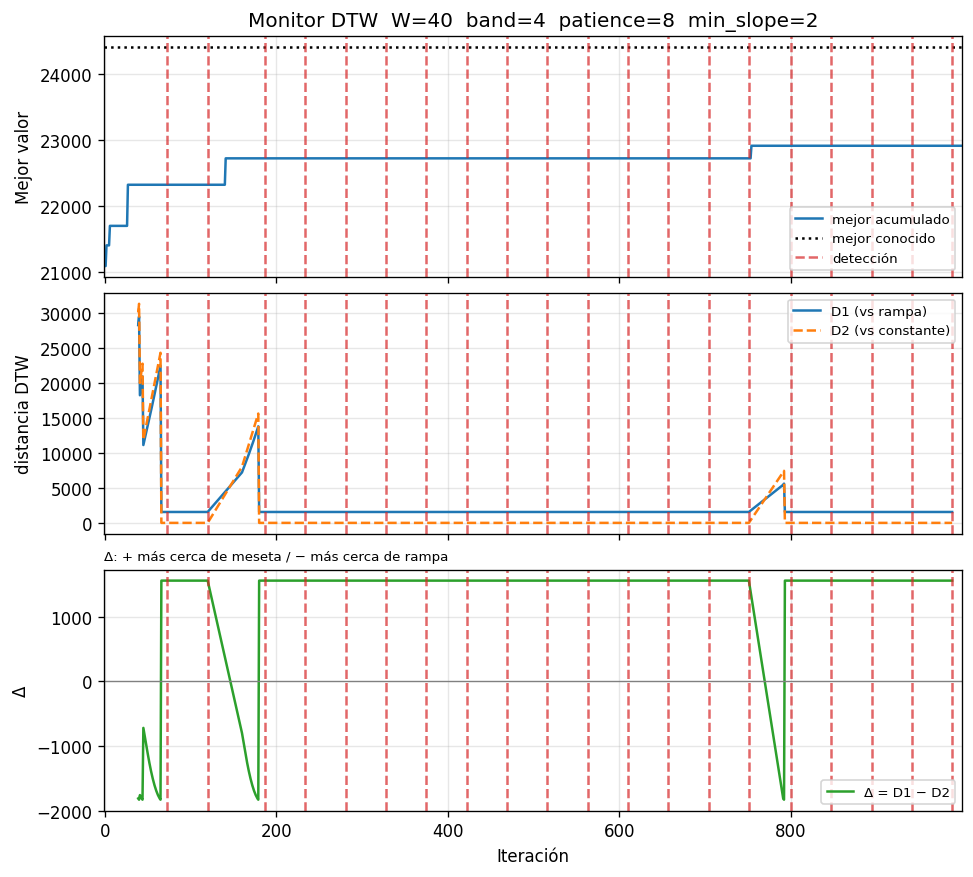

In [14]:
# Sin sliders, esta celda grafica. Con sliders, no repite el gráfico salvo que cambies min_slope_.
W_, band_, patience_ = 40, 4, 8
min_slope_ = 2.0          # prueba 0.5 y 20, y vuelve a ejecutar esta celda
if (not WIDGETS_OK) or min_slope_ != 2.0:
    print("Detecciones:", graficar_monitor(hist_gwo, replace(CFG_DEFECTO, W=W_, band=band_, patience=patience_, min_slope=min_slope_)))
else:
    print("Los sliders de arriba ya grafican. Cambia min_slope_ y vuelve a ejecutar si quieres otra pendiente.")

print("\nBarrido rápido (misma corrida de GWO):")
for W in [20, 40, 60]:
    for pat in [3, 8]:
        print(f"  W={W:2d} patience={pat}: detecciones {analizar(hist_gwo, replace(CFG_DEFECTO, W=W, band=max(1, W // 10), patience=pat))[3]}")


## 5. Reaccionar con parámetros

Ahora la búsqueda reacciona a lo que marca el monitor. GWO y DE (*Differential Evolution*) corren juntos en cada generación, sobre la misma población. Hay dos perfiles de parámetros:

- **explotación**: busca cerca de lo que ya encontró ($a=0{,}5$, $F=0{,}5$, $CR=0{,}9$),
- **exploración**: salta más lejos ($a=2{,}0$, $F=0{,}9$, $CR=0{,}3$).

En los dos perfiles $G_3=0{,}1$.

La regla de cambio, `siguiente_perfil`, es la del paper y ya viene escrita. En explotación, si el monitor dispara, la búsqueda pasa a exploración. En exploración, si hubo una mejora reciente, vuelve a explotación. Cada cambio reinicia el monitor.

La corrida dura 1000 generaciones. En cada una se evalúan GWO y DE.

El monitor no evalúa si la reacción sirvió: solo vuelve a mirar la curva.

Primero se comparan dos corridas con la misma semilla: solo explotación y parámetros+DTW. Después se dibuja la figura de diagnóstico temporal de los papers (`temporal_diagnostics`).


In [15]:
#@title Perfiles y búsqueda GWO-DE con reacción { display-mode: "form" }
INICIO = "explotación"  #@param ["explotación", "exploración"]

# Valores de gwo_de_dtw/config.py (EXPLOIT_* / EXPLORE_*).
PERFILES = {
    "explotación": {"a": 0.5, "F": 0.5, "CR": 0.9, "G3": 0.1},
    "exploración": {"a": 2.0, "F": 0.9, "CR": 0.3, "G3": 0.1},
}

def generaciones_del_modo(modo):
    # Mismo presupuesto EVALUACIONES; en parametros hay 2 candidatos × 2 reparaciones LB2 por individuo.
    ev_por_gen = (4 if modo == "parametros" else 2) * num_individuos
    return (EVALUACIONES - num_individuos) // ev_por_gen

# Monitor escalado al mismo tramo de evaluaciones (cada generación gasta el doble).
CFG_PARAMETROS = replace(CFG_DEFECTO)  # mismas perillas que la sección 4; 1000 generaciones

def siguiente_perfil(perfil_actual, out, cfg=CFG_DEFECTO):
    if not out.get("listo"):
        return perfil_actual
    if perfil_actual == "explotación":
        return "exploración" if out["disparo"] else perfil_actual
    return "explotación" if out["sin_mejora"] < cfg.plateau_max else perfil_actual

def de_candidato(i, poblacion, rng, F=0.5, CR=0.9):
    # Un candidato DE/rand/1/bin: v = x_r1 + F*(x_r2 - x_r3), cruce binomial, un índice asegurado.
    tam, n_ = poblacion.shape
    otros = [j for j in range(tam) if j != i]
    r1, r2, r3 = rng.choice(otros, 3, replace=False)
    v = np.clip(poblacion[r1] + F * (poblacion[r2] - poblacion[r3]), -V_max, V_max)
    mascara = rng.random(n_) < CR
    mascara[rng.integers(0, n_)] = True
    return np.where(mascara, v, poblacion[i])

def programacion_G(it, n_gen):
    G1 = G1_f + (G1_i - G1_f) / (1 - n_gen) * (it - n_gen)
    G2 = G2_f + (G2_i - G2_f) / (1 - n_gen) * (it - n_gen)
    G3 = G3_f + (G3_i - G3_f) / (1 - n_gen) * (it - n_gen)
    return G1, G2, G3

def correr_parametros(semilla, perfil_inicial, al_iterar=None):
    # GWO y DE en cada generación, misma población (híbrido competitivo de hybrid.py).
    # a, F, CR y G3 salen del perfil de parámetros; a no decae. G1 y G2 siguen la programación del curso.
    n_gen = num_iteraciones
    rng = np.random.default_rng(semilla)
    x_real = rng.uniform(-V_max, V_max, (num_individuos, n))
    x_bin = np.zeros((num_individuos, n), dtype=int)
    fit = np.empty(num_individuos)
    mejor_valor = -np.inf
    for i in range(num_individuos):
        x_bin[i], fit[i] = reparar_solucion((x_real[i] > 0).astype(int), p, r, b, indices_ascendentes)
        if fit[i] > mejor_valor:
            mejor_valor = fit[i]
    perfil = perfil_inicial
    historial = []
    for iteracion in range(n_gen):
        G1, G2, _G3_prog = programacion_G(iteracion, n_gen)
        par = PERFILES[perfil]
        a, F_, CR_, G3 = par["a"], par["F"], par["CR"], par["G3"]
        orden = np.argsort(fit)[::-1]
        lideres = x_real[orden[:3]].copy()
        for i in range(num_individuos):
            u_gwo = gwo_candidato(x_real[i], lideres, a, rng)
            u_de = de_candidato(i, x_real, rng, F=F_, CR=CR_)
            b_gwo, f_gwo = lb2_binarizar(u_gwo, x_bin[i], rng, G1, G2, G3)
            b_de, f_de = lb2_binarizar(u_de, x_bin[i], rng, G1, G2, G3)
            if f_gwo >= f_de:
                u, bits, val = u_gwo, b_gwo, f_gwo
            else:
                u, bits, val = u_de, b_de, f_de
            if val >= fit[i]:
                x_real[i], x_bin[i], fit[i] = u, bits, val
                if val > mejor_valor:
                    mejor_valor = val
        historial.append(float(mejor_valor))
        if al_iterar is not None:
            nuevo = al_iterar(iteracion, mejor_valor)
            if nuevo is not None:
                perfil = nuevo   # rige desde la generación siguiente; población y mejor se mantienen
    return np.array(historial)

def parametros_dtw(semilla, cfg=CFG_PARAMETROS, inicio=None):
    mon = MonitorDTW(cfg)
    inicio = inicio if inicio in PERFILES else INICIO
    estado = {"perfil": inicio, "cambios": [(0, inicio)]}
    nanW = np.full(cfg.W, np.nan)
    traza = {k: [] for k in ("perfil_usado", "decision", "listo", "adaptativo",
                             "D1", "D2", "delta", "theta_r", "theta_c", "theta_delta",
                             "X", "R", "C")}
    def al_iterar(it, mejor):
        usado = estado["perfil"]
        out = mon.update(mejor)
        if out["listo"]:
            X = np.array(mon.serie[-cfg.W:], dtype=float)
            R = X[0] + pendiente_rampa(X, cfg) * np.arange(cfg.W)
            C = np.full(cfg.W, X[0])
            adaptativo = bool(cfg.adaptativo and len(mon.h_D1) >= 10)
        else:
            X = R = C = nanW
            adaptativo = False
        nuevo = siguiente_perfil(estado["perfil"], out, cfg)
        if nuevo != estado["perfil"]:
            estado["perfil"] = nuevo
            estado["cambios"].append((it, nuevo))
            mon.reiniciar_ventana()
            decision, retorno = nuevo, nuevo
        else:
            decision, retorno = estado["perfil"], None
        traza["perfil_usado"].append(usado)
        traza["decision"].append(decision)
        traza["listo"].append(bool(out["listo"]))
        traza["adaptativo"].append(adaptativo)
        for clave, valor in (("D1", out.get("D1", np.nan)), ("D2", out.get("D2", np.nan)),
                             ("delta", out.get("delta", np.nan)), ("theta_r", out.get("theta_r", np.nan)),
                             ("theta_c", out.get("theta_c", np.nan)), ("theta_delta", out.get("theta_delta", np.nan))):
            traza[clave].append(valor)
        traza["X"].append(np.array(X, dtype=float))
        traza["R"].append(np.array(R, dtype=float))
        traza["C"].append(np.array(C, dtype=float))
        return retorno
    hist = correr_parametros(semilla, perfil_inicial=estado["perfil"], al_iterar=al_iterar)
    return hist, estado["cambios"], traza

COLORES_PERFIL = {"explotación": "tab:blue", "exploración": "tab:orange"}

def franjas(ax, cambios, largo):
    # Una franja de color por tramo (perfil activo) y una línea en cada cambio.
    limites = [c[0] for c in cambios] + [largo]
    for k_t, (x0, etq) in enumerate(cambios):
        col = COLORES_PERFIL.get(etq, "0.5")
        ax.axvspan(limites[k_t], limites[k_t + 1], color=col, alpha=0.13, lw=0)
    for x, _ in cambios[1:]:
        ax.axvline(x, color="0.3", ls="--", lw=1)

print(f"INICIO={INICIO}  |  {num_iteraciones} generaciones")
print(f"Monitor: W={CFG_PARAMETROS.W}, band={CFG_PARAMETROS.band}, patience={CFG_PARAMETROS.patience}, "
      f"plateau_max={CFG_PARAMETROS.plateau_max}, min_slope={CFG_PARAMETROS.min_slope}")


INICIO=explotación  |  1000 generaciones
Monitor: W=40, band=4, patience=8, plateau_max=15, min_slope=2.0


Solo explotación, semilla 0: mejor = 23260
Parámetros+DTW,   semilla 0: mejor = 23285  (96.8 s)
Cambios de perfil: 3
Tramos (generación de inicio, perfil activo): [(0, 'explotación'), (84, 'exploración'), (164, 'explotación'), (246, 'exploración')]


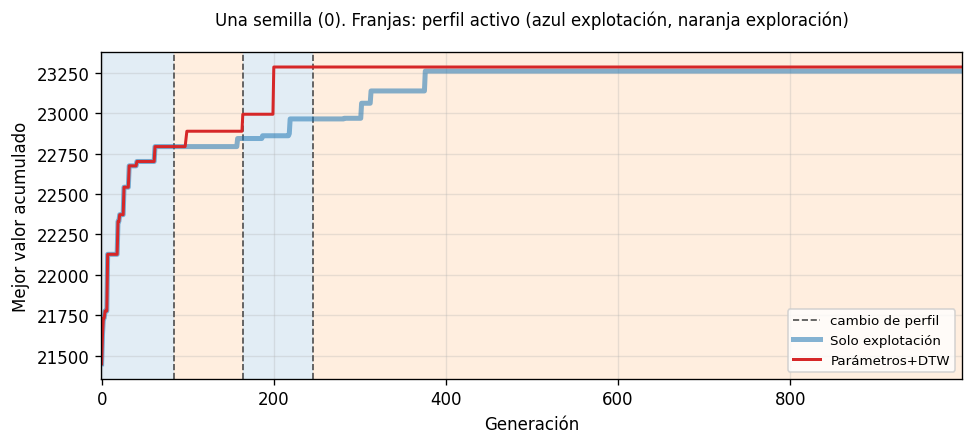

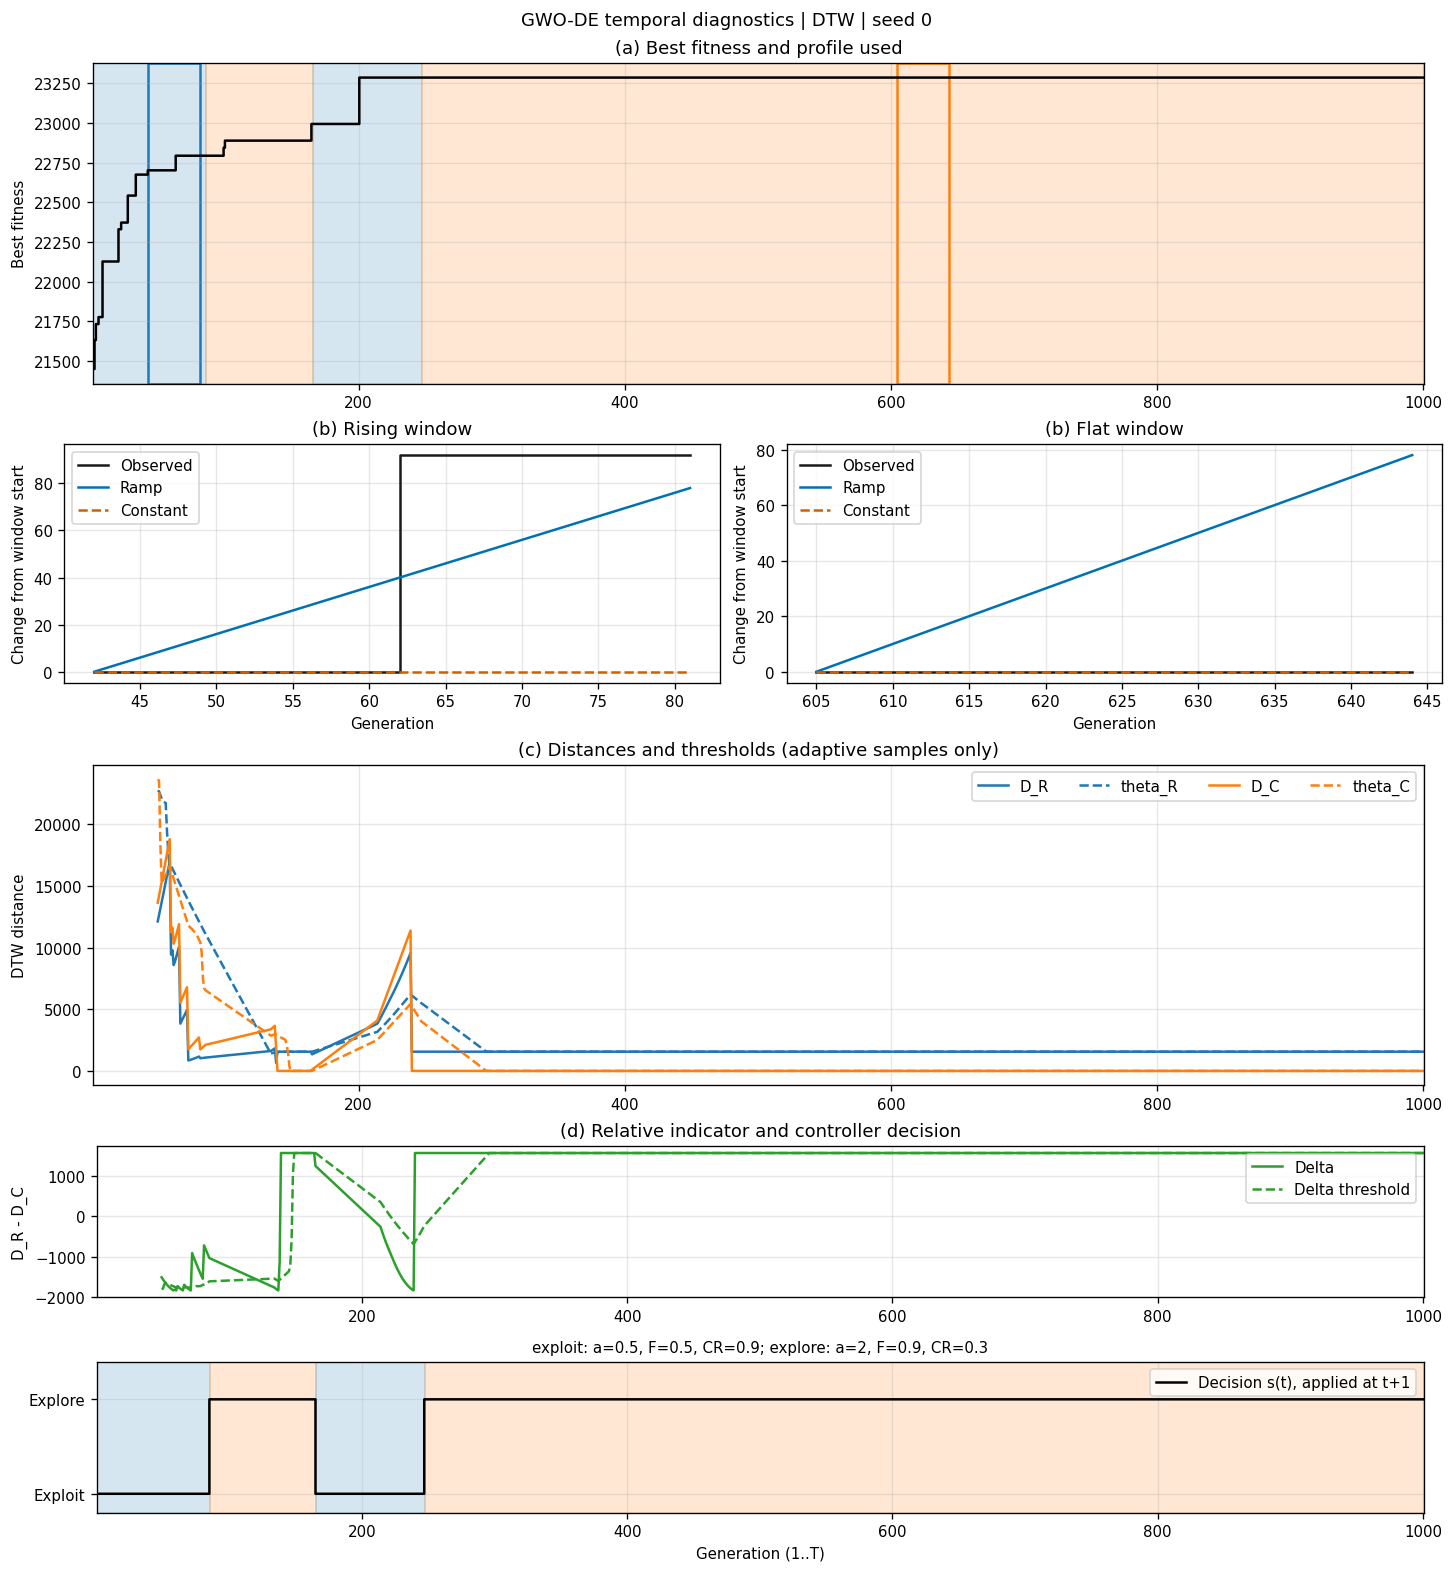

In [16]:
#@title Correr la comparación y dibujar las figuras { display-mode: "form" }
t0 = time.time()
hist_ref = correr_parametros(SEMILLA, "explotación")
hist_dtw, cambios_semilla, traza_dtw = parametros_dtw(SEMILLA)
print(f"Solo explotación, semilla {SEMILLA}: mejor = {hist_ref[-1]:.0f}")
print(f"Parámetros+DTW,   semilla {SEMILLA}: mejor = {hist_dtw[-1]:.0f}  ({time.time()-t0:.1f} s)")
print(f"Cambios de perfil: {len(cambios_semilla) - 1}")
print("Tramos (generación de inicio, perfil activo):", cambios_semilla)

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
franjas(ax, cambios_semilla, len(hist_dtw))
ax.plot([], [], color="0.3", ls="--", lw=1, label="cambio de perfil")
ax.plot(hist_ref, color="tab:blue", lw=3.0, alpha=0.55, label="Solo explotación")  # gruesa: si coincide, se ve debajo
ax.plot(hist_dtw, color="tab:red", lw=1.8, label="Parámetros+DTW")
ax.set_xlabel("Generación"); ax.set_ylabel("Mejor valor acumulado")
ax.set_title(f"Una semilla ({SEMILLA}). Franjas: perfil activo (azul explotación, naranja exploración)", fontsize=10, pad=16)
ax.set_xlim(-0.5, len(hist_dtw) - 0.5)
ax.legend(fontsize=8, loc="lower right", frameon=True); plt.show()

def figura_temporal_diagnostics(hist, traza, cfg, semilla):
    # La figura de gwo_de_dtw/plots/temporal.py (temporal_diagnostics.png). No es otra.
    n, W = len(hist), cfg.W
    t = np.arange(1, n + 1)
    perfil = np.array(["exploit" if p == "explotación" else "explore" for p in traza["perfil_usado"]])
    decision = np.array([1 if p == "exploración" else 0 for p in traza["decision"]])
    ready = np.array(traza["listo"], dtype=bool)
    adapt = np.array(traza["adaptativo"], dtype=bool)
    X, R, C = (np.vstack(traza[k]) for k in ("X", "R", "C"))
    serie = {k: np.asarray(traza[k], dtype=float) for k in ("D1", "D2", "delta", "theta_r", "theta_c", "theta_delta")}
    colores = {"exploit": "#1f77b4", "explore": "#ff7f0e"}
    segmentos = []
    ini = 0
    for i in range(1, n + 1):
        if i == n or perfil[i] != perfil[ini]:
            segmentos.append((perfil[ini], ini, i))
            ini = i

    def sombra(ax):
        for nombre, a, b in segmentos:
            ax.axvspan(a + .5, b + .5, color=colores[nombre], alpha=.18)

    subida = X[:, -1] - X[:, 0]
    mode = (perfil == "explore").astype(int)
    ascendentes = np.flatnonzero(ready & (subida > 0) & (mode == 0))
    if not ascendentes.size:
        ascendentes = np.flatnonzero(ready & (subida > 0))
    plana = ready & (subida == 0) & (mode == 1)
    if not plana.any():
        plana = ready & (subida == 0)
    mejor, ini = [], None
    for i, valor in enumerate(list(plana) + [False]):
        if valor and ini is None:
            ini = i
        elif not valor and ini is not None:
            if i - ini > len(mejor):
                mejor = list(range(ini, i))
            ini = None
    alza_rampa = R[:, -1] - R[:, 0]
    idx_sube = int(ascendentes[np.argmin(np.abs(subida[ascendentes] - alza_rampa[ascendentes]))]) if ascendentes.size else None
    idx_plana = mejor[len(mejor) // 2] if mejor else None

    with plt.rc_context({"font.size": 9}):
        fig = plt.figure(figsize=(12, 13), layout="constrained")
        grid = fig.add_gridspec(4, 1, height_ratios=[1, 1, 1, 1.4])
        ax_a = fig.add_subplot(grid[0])
        ventanas = grid[1].subgridspec(1, 2)
        ax_bp, ax_bc = fig.add_subplot(ventanas[0]), fig.add_subplot(ventanas[1])
        ax_c = fig.add_subplot(grid[2], sharex=ax_a)
        abajo = grid[3].subgridspec(2, 1)
        ax_d, ax_s = fig.add_subplot(abajo[0], sharex=ax_a), fig.add_subplot(abajo[1], sharex=ax_a)
        sombra(ax_a); sombra(ax_s)
        ax_a.step(t, hist, where="mid", color="black")
        ax_a.set(title="(a) Best fitness and profile used", ylabel="Best fitness")
        for ax, idx, titulo, color in ((ax_bp, idx_sube, "Rising window", "tab:blue"), (ax_bc, idx_plana, "Flat window", "tab:orange")):
            ax.set(title="(b) " + titulo, xlabel="Generation", ylabel="Change from window start")
            if idx is None:
                ax.text(.5, .5, "No eligible window", transform=ax.transAxes, ha="center")
                continue
            xs = np.arange(idx - W + 2, idx + 2)
            ax_a.axvspan(xs[0], xs[-1], facecolor="none", edgecolor=color, linewidth=1.5)
            for clave, y, etiqueta, estilo, col in (("X", X[idx], "Observed", "-", "#1a1a1a"), ("R", R[idx], "Ramp", "-", "#0072B2"), ("C", C[idx], "Constant", "--", "#D55E00")):
                ax.plot(xs, y - y[0], estilo, color=col, label=etiqueta, drawstyle="steps-pre" if clave == "X" else "default")
            ax.legend()
        for clave, etiqueta, col, estilo in (("D1", "D_R", "tab:blue", "-"), ("theta_r", "theta_R", "tab:blue", "--"), ("D2", "D_C", "tab:orange", "-"), ("theta_c", "theta_C", "tab:orange", "--")):
            ok = np.isfinite(serie[clave]) & adapt
            ax_c.plot(t[ok], serie[clave][ok], color=col, linestyle=estilo, label=etiqueta)
        ax_c.set(title="(c) Distances and thresholds (adaptive samples only)", ylabel="DTW distance")
        ax_c.legend(ncol=4)
        for clave, etiqueta, estilo in (("delta", "Delta", "-"), ("theta_delta", "Delta threshold", "--")):
            ok = np.isfinite(serie[clave]) & adapt
            ax_d.plot(t[ok], serie[clave][ok], estilo, label=etiqueta, color="tab:green")
        ax_d.set(title="(d) Relative indicator and controller decision", ylabel="D_R - D_C")
        ax_d.legend()
        ax_s.step(t, decision, where="post", color="black", label="Decision s(t), applied at t+1")
        ax_s.set(yticks=[0, 1], yticklabels=["Exploit", "Explore"], ylim=(-.2, 1.4), xlabel="Generation (1..T)")
        ax_s.legend(loc="upper right")
        usados = []
        for nombre in perfil:
            if nombre not in usados:
                usados.append(nombre)
        partes = []
        for nombre in usados:
            par = PERFILES["explotación" if nombre == "exploit" else "exploración"]
            partes.append(f"{nombre}: a={par['a']:g}, F={par['F']:g}, CR={par['CR']:g}")
        ax_s.set_title("; ".join(partes), fontsize=9)
        for ax in (ax_a, ax_c, ax_d, ax_s):
            ax.set_xlim(.5, n + .5)
        fig.suptitle(f"GWO-DE temporal diagnostics | DTW | seed {semilla}")
        plt.show()

figura_temporal_diagnostics(hist_dtw, traza_dtw, CFG_PARAMETROS, SEMILLA)


**Tu turno:** en el primer gráfico, ¿la curva roja subió después de que empezó una franja naranja de exploración? ¿Cuántos cambios de perfil hubo? Después cambia `INICIO` a exploración en el campo de la celda de perfiles y vuelve a ejecutar esa celda y la siguiente.


## 6. HRES2: el mismo monitor en otro problema

HRES2 es el diseño de un sistema que genera electricidad con viento y sol, la guarda en una batería y la usa en un electrolizador para producir hidrógeno. Se busca el menor costo de la energía, el **LCOE** (en CNY/kWh): este problema **minimiza**.

En el MKP cada solución era una lista de bits. En HRES2 es un vector de 4 números, y GWO-DE los mueve igual que en el MKP:

| Coordenada | Qué es | Lectura |
|---|---|---|
| `x[0]` | viento, MW | de 0 a 200. La solar es lo que falta: 200 − viento. |
| `x[1]` | unidades de electrolizador | de 10 a 20, se redondea. Cada unidad son 5 MW. |
| `x[2]` | batería, MW | de 0 a 50, en pasos de 5. |
| `x[3]` | duración de la batería | 0, 1 o 2 → 1 h, 2 h o 4 h. Energía = potencia × horas. |

La celda siguiente carga el modelo de HRES2: un año de clima sintético, hora por hora (8760 horas), el despacho de la energía y los costos. Es el mismo modelo del paper. Puedes ejecutarla sin leerla.


In [17]:
#@title Modelo HRES2 (el mismo del paper) { display-mode: "form" }
# Modelo HRES2, copiado de HRES2-H2/wpeb_model.py. No hace falta leerlo.
import math
import pandas as pd
from dataclasses import dataclass, asdict
from typing import Dict, Tuple, Optional

# ── Configuración Predeterminada ───────────────────────────────────────────────

CONFIG_DEFAULT = {
    "lat": 41.70,
    "lon": 110.43,
    "total_generation_capacity_mw": 200.0,
    "agsr_max": 0.20,
    "electrolyzer_ratio_max": 0.50,

    "electrolyzer_unit_mw": 5.0,
    "min_electrolyzer_units": 10,  # 50 MW
    "max_electrolyzer_units": 20,  # 100 MW

    "battery_power_min_mw": 0.0,
    "battery_power_max_mw": 50.0,
    "battery_duration_candidates_h": [1.0, 2.0, 4.0],

    "h2_hhv_kwh_per_kg": 39.4,
    "electrolyzer_efficiency": 0.75,
    "electrolyzer_min_load_ratio": 0.30,

    "project_lifetime_years": 25,
    "real_discount_rate": 0.0435,

    "wind_turbine_rated_mw": 5.0,
    "wind_cut_in_ms": 2.5,
    "wind_rated_ms": 10.5,
    "wind_cut_out_ms": 25.0,

    "pv_dc_ac_ratio": 1.2,
    "pv_temp_coeff_pct_per_c": -0.5,
    "pv_noct_c": 47.0,
    "pv_stc_efficiency_pct": 13.0,
    "pv_derating_factor": 0.90,

    "converter_efficiency": 0.95,
    "battery_roundtrip_efficiency": 0.90,
}

COSTS_DEFAULT = {
    "wind_capex_cny_per_kw": 5917.0,
    "wind_replacement_cny_per_kw": 0.0,
    "wind_om_cny_per_kw_year": 40.2,
    "wind_life_years": 25,

    "pv_capex_cny_per_kw": 4633.0,
    "pv_replacement_cny_per_kw": 0.0,
    "pv_om_cny_per_kw_year": 17.6,
    "pv_life_years": 25,

    "electrolyzer_capex_cny_per_kw": 6964.0,
    "electrolyzer_replacement_cny_per_kw": 5969.14,
    "electrolyzer_om_cny_per_kw_year": 208.92,
    "electrolyzer_life_years": 15,

    "battery_capex_cny_per_kw": 2549.0,
    "battery_replacement_cny_per_kw": 500.0,
    "battery_om_cny_per_kw_year": 10.0,
    "battery_life_years": 10,
}


# ── Estructura de Resultado ───────────────────────────────────────────────────

@dataclass
class ExtendedSimulationResult:
    wind_mw: float
    pv_mw: float
    electrolyzer_mw: float
    n_el_units: int
    battery_mw: float
    battery_mwh: float
    battery_duration_h: float
    feasible: bool
    agsr: float
    total_wind_mwh: float
    total_pv_mwh: float
    total_renewable_mwh: float
    total_grid_sales_mwh: float
    total_electrolyzer_load_mwh: float
    electrolyzer_cf: float
    total_h2_kg: float
    npc_cny: float
    annualized_cost_cny: float
    lcoe_cny_per_kwh: float
    lcoh_cny_per_kg: float
    curtailment_mwh: float
    battery_throughput_mwh: float


# ── Modelos Financieros y Perfiles Precalculados ──────────────────────────────

def crf(i: float, n: int) -> float:
    return (i * (1 + i) ** n) / (((1 + i) ** n) - 1)


def present_value_of_replacements(capacity_kw: float, replacement_cost_per_kw: float,
                                  life_years: int, project_years: int, discount_rate: float) -> float:
    years = list(range(life_years, project_years, life_years))
    return sum((capacity_kw * replacement_cost_per_kw) / ((1 + discount_rate) ** y) for y in years)


def present_value_of_om(capacity_kw: float, om_per_kw_year: float,
                        project_years: int, discount_rate: float) -> float:
    return sum((capacity_kw * om_per_kw_year) / ((1 + discount_rate) ** y) for y in range(1, project_years + 1))


def npc_from_capacities(wind_mw: float, pv_mw: float, electrolyzer_mw: float,
                        battery_mw: float, config: Dict, costs: Dict) -> float:
    i = config["real_discount_rate"]
    n = config["project_lifetime_years"]

    def comp(cap_mw, capex, repl, om, life):
        cap_kw = cap_mw * 1000.0
        return (
            cap_kw * capex
            + present_value_of_replacements(cap_kw, repl, life, n, i)
            + present_value_of_om(cap_kw, om, n, i)
        )

    npc = 0.0
    npc += comp(wind_mw, costs["wind_capex_cny_per_kw"], costs["wind_replacement_cny_per_kw"],
                costs["wind_om_cny_per_kw_year"], costs["wind_life_years"])
    npc += comp(pv_mw, costs["pv_capex_cny_per_kw"], costs["pv_replacement_cny_per_kw"],
                costs["pv_om_cny_per_kw_year"], costs["pv_life_years"])
    npc += comp(electrolyzer_mw, costs["electrolyzer_capex_cny_per_kw"], costs["electrolyzer_replacement_cny_per_kw"],
                costs["electrolyzer_om_cny_per_kw_year"], costs["electrolyzer_life_years"])
    npc += comp(battery_mw, costs["battery_capex_cny_per_kw"], costs["battery_replacement_cny_per_kw"],
                costs["battery_om_cny_per_kw_year"], costs["battery_life_years"])
    return npc


def precalculate_profiles(df: pd.DataFrame, config: Dict) -> Tuple[np.ndarray, np.ndarray]:
    """Precalcula los perfiles unitarios (por MW instalado) de generación eólica y solar."""
    # Solar
    ghi = df["ghi_kwh_m2"].values
    t_amb = df["t2m_c"].values
    t_cell = t_amb + (config["pv_noct_c"] - 20.0) / 0.8 * ghi
    gamma = config["pv_temp_coeff_pct_per_c"] / 100.0
    temp_factor = 1.0 + gamma * (t_cell - 25.0)
    rel_pv = ghi * config["pv_derating_factor"] * np.maximum(temp_factor, 0.0)
    pv_unit = np.clip(rel_pv, 0.0, 1.0)

    # Eólica
    ws = df["ws50m"].values
    cut_in = config["wind_cut_in_ms"]
    rated = config["wind_rated_ms"]
    cut_out = config["wind_cut_out_ms"]
    wind_unit = np.zeros_like(ws, dtype=float)
    m1 = (ws >= cut_in) & (ws < rated)
    m2 = (ws >= rated) & (ws < cut_out)
    wind_unit[m1] = (ws[m1]**3 - cut_in**3) / (rated**3 - cut_in**3)
    wind_unit[m2] = 1.0
    wind_unit = np.clip(wind_unit, 0.0, 1.0)

    return wind_unit, pv_unit


try:
    from numba import njit
except ImportError:
    def njit(func):
        return func


# ── Simulación Rápida Numba/Fast C-style ───────────────────────────────────────

@njit
def _fast_dispatch_simulation(
    p_gen: np.ndarray,
    electrolyzer_mw: float,
    battery_mw: float,
    battery_mwh: float,
    min_elz: float,
    eta_ch: float,
    eta_dis: float,
) -> Tuple[float, float, float, float]:

    """Bucle de despacho horario optimizado de alta velocidad."""
    soc = 0.0
    soc_max = battery_mwh
    p_batt_max = battery_mw

    total_grid = 0.0
    total_elz = 0.0
    curtailment = 0.0
    batt_tp = 0.0

    for gen in p_gen:
        p_elz = 0.0
        p_charge = 0.0
        p_discharge = 0.0
        p_grid = 0.0

        if gen >= min_elz and electrolyzer_mw > 0:
            p_elz = gen if gen <= electrolyzer_mw else electrolyzer_mw
        elif electrolyzer_mw > 0 and p_batt_max > 0 and soc > 0:
            max_dis = p_batt_max if p_batt_max < soc * eta_dis else soc * eta_dis
            if gen + max_dis >= min_elz:
                p_discharge = max_dis if max_dis < (electrolyzer_mw - gen) else (electrolyzer_mw - gen)
                p_elz = gen + p_discharge if (gen + p_discharge) < electrolyzer_mw else electrolyzer_mw

        surplus = gen + p_discharge - p_elz

        if surplus > 1e-12 and p_batt_max > 0 and soc_max > 0:
            max_ch_soc = (soc_max - soc) / eta_ch if eta_ch > 0 else 0.0
            p_charge = surplus
            if p_batt_max < p_charge:
                p_charge = p_batt_max
            if max_ch_soc < p_charge:
                p_charge = max_ch_soc

            soc += p_charge * eta_ch
            surplus -= p_charge
            batt_tp += p_charge

        if p_discharge > 0:
            soc -= p_discharge / eta_dis
            if soc < 0.0:
                soc = 0.0
            batt_tp += p_discharge

        if surplus > 1e-12:
            p_grid = surplus

        total_grid += p_grid
        total_elz += p_elz

    return total_grid, total_elz, curtailment, batt_tp


# ── Simulación Principal ──────────────────────────────────────────────────────

def simulate_wpeb_fast(
    wind_unit: np.ndarray,
    pv_unit: np.ndarray,
    wind_mw: float,
    n_el_units: int,
    battery_mw: float,
    battery_duration_h: float,
    config: Dict = CONFIG_DEFAULT,
    costs: Dict = COSTS_DEFAULT,
) -> ExtendedSimulationResult:
    total_capacity = config["total_generation_capacity_mw"]
    pv_mw = total_capacity - wind_mw
    electrolyzer_mw = n_el_units * config["electrolyzer_unit_mw"]
    battery_mwh = battery_mw * battery_duration_h

    if wind_mw < 0 or pv_mw < 0 or abs(wind_mw + pv_mw - total_capacity) > 1e-6:
        return ExtendedSimulationResult(wind_mw, pv_mw, electrolyzer_mw, n_el_units, battery_mw, battery_mwh,
                                        battery_duration_h, False, np.nan, 0,0,0,0,0,0,0,0,0,np.inf,np.inf,0,0)

    if n_el_units < config["min_electrolyzer_units"] or n_el_units > config["max_electrolyzer_units"]:
        return ExtendedSimulationResult(wind_mw, pv_mw, electrolyzer_mw, n_el_units, battery_mw, battery_mwh,
                                        battery_duration_h, False, np.nan, 0,0,0,0,0,0,0,0,0,np.inf,np.inf,0,0)

    if battery_mw < config["battery_power_min_mw"] or battery_mw > config["battery_power_max_mw"]:
        return ExtendedSimulationResult(wind_mw, pv_mw, electrolyzer_mw, n_el_units, battery_mw, battery_mwh,
                                        battery_duration_h, False, np.nan, 0,0,0,0,0,0,0,0,0,np.inf,np.inf,0,0)

    if battery_duration_h not in config["battery_duration_candidates_h"]:
        return ExtendedSimulationResult(wind_mw, pv_mw, electrolyzer_mw, n_el_units, battery_mw, battery_mwh,
                                        battery_duration_h, False, np.nan, 0,0,0,0,0,0,0,0,0,np.inf,np.inf,0,0)

    if electrolyzer_mw > config["electrolyzer_ratio_max"] * total_capacity:
        return ExtendedSimulationResult(wind_mw, pv_mw, electrolyzer_mw, n_el_units, battery_mw, battery_mwh,
                                        battery_duration_h, False, np.nan, 0,0,0,0,0,0,0,0,0,np.inf,np.inf,0,0)

    p_gen = wind_mw * wind_unit + pv_mw * pv_unit
    min_elz = config["electrolyzer_min_load_ratio"] * electrolyzer_mw

    eta_rt = config["battery_roundtrip_efficiency"]
    eta_ch = math.sqrt(eta_rt)
    eta_dis = math.sqrt(eta_rt)

    total_grid_sales_mwh, total_elz_mwh, curtailment_mwh, batt_tp = _fast_dispatch_simulation(
        p_gen=p_gen,
        electrolyzer_mw=electrolyzer_mw,
        battery_mw=battery_mw,
        battery_mwh=battery_mwh,
        min_elz=min_elz,
        eta_ch=eta_ch,
        eta_dis=eta_dis,
    )

    total_wind_mwh = float(np.sum(wind_mw * wind_unit))
    total_pv_mwh = float(np.sum(pv_mw * pv_unit))
    total_renewable_mwh = total_wind_mwh + total_pv_mwh
    electrolyzer_cf = total_elz_mwh / (electrolyzer_mw * len(p_gen)) if electrolyzer_mw > 0 else 0.0

    agsr = (total_grid_sales_mwh / total_renewable_mwh) if total_renewable_mwh > 0 else np.inf
    feasible = agsr <= config["agsr_max"]

    total_h2_kg = total_elz_mwh * 1000.0 * config["electrolyzer_efficiency"] / config["h2_hhv_kwh_per_kg"]

    npc_cny = npc_from_capacities(wind_mw, pv_mw, electrolyzer_mw, battery_mw, config, costs)
    annualized_cost_cny = npc_cny * crf(config["real_discount_rate"], config["project_lifetime_years"])

    delivered_kwh = (total_elz_mwh + total_grid_sales_mwh) * 1000.0
    lcoe = annualized_cost_cny / delivered_kwh if feasible and delivered_kwh > 0 else np.inf
    lcoh = annualized_cost_cny / total_h2_kg if feasible and total_h2_kg > 0 else np.inf

    return ExtendedSimulationResult(
        wind_mw=wind_mw,
        pv_mw=pv_mw,
        electrolyzer_mw=electrolyzer_mw,
        n_el_units=int(n_el_units),
        battery_mw=battery_mw,
        battery_mwh=battery_mwh,
        battery_duration_h=battery_duration_h,
        feasible=bool(feasible),
        agsr=float(agsr),
        total_wind_mwh=total_wind_mwh,
        total_pv_mwh=total_pv_mwh,
        total_renewable_mwh=total_renewable_mwh,
        total_grid_sales_mwh=total_grid_sales_mwh,
        total_electrolyzer_load_mwh=total_elz_mwh,
        electrolyzer_cf=float(electrolyzer_cf),
        total_h2_kg=float(total_h2_kg),
        npc_cny=float(npc_cny),
        annualized_cost_cny=float(annualized_cost_cny),
        lcoe_cny_per_kwh=float(lcoe),
        lcoh_cny_per_kg=float(lcoh),
        curtailment_mwh=float(curtailment_mwh),
        battery_throughput_mwh=float(batt_tp),
    )


def decode_solution(x: np.ndarray, config: Dict = CONFIG_DEFAULT) -> Dict:
    x_clip = np.copy(x)
    wind_mw = float(np.clip(x_clip[0], 0.0, config["total_generation_capacity_mw"]))

    n_el_raw = float(np.clip(x_clip[1], config["min_electrolyzer_units"], config["max_electrolyzer_units"]))
    n_el_units = int(round(n_el_raw))

    batt_raw = float(np.clip(x_clip[2], config["battery_power_min_mw"], config["battery_power_max_mw"]))
    battery_mw = float(round(batt_raw / config.get("battery_power_step_mw", 5.0)) * config.get("battery_power_step_mw", 5.0))

    dur_candidates = config["battery_duration_candidates_h"]
    idx_raw = float(np.clip(x_clip[3], 0.0, len(dur_candidates) - 1))
    dur_idx = int(round(idx_raw))
    battery_duration_h = float(dur_candidates[dur_idx])

    return {
        "wind_mw": wind_mw,
        "pv_mw": config["total_generation_capacity_mw"] - wind_mw,
        "n_el_units": n_el_units,
        "electrolyzer_mw": n_el_units * config["electrolyzer_unit_mw"],
        "battery_mw": battery_mw,
        "battery_duration_h": battery_duration_h,
        "battery_mwh": battery_mw * battery_duration_h,
    }


def generate_synthetic_tmy_8760() -> pd.DataFrame:
    np.random.seed(2008)
    hours = 8760
    timestamps = pd.date_range("2008-01-01 00:00", periods=hours, freq="h")
    t_hour = np.arange(hours)

    day_of_year = t_hour / 24.0
    solar_decl = 0.4 * np.sin(2 * np.pi * (day_of_year - 80) / 365.0)
    hour_of_day = t_hour % 24
    solar_elevation = np.maximum(0.0, np.sin(np.pi * (hour_of_day - 6) / 12.0)) * (0.6 + solar_decl)
    ghi = np.maximum(0.0, solar_elevation * 1.0 + np.random.normal(0, 0.05, hours))

    ws_base = np.random.weibull(2.1, hours) * 7.8
    ws_diurnal = 1.0 + 0.15 * np.cos(2 * np.pi * (hour_of_day - 2) / 24.0)
    ws50m = np.clip(ws_base * ws_diurnal, 0.0, 25.0)

    t2m_c = 10.0 + 15.0 * np.sin(2 * np.pi * (day_of_year - 100) / 365.0) + 5.0 * np.sin(2 * np.pi * (hour_of_day - 14) / 24.0)

    return pd.DataFrame({
        "timestamp": timestamps,
        "ws50m": ws50m,
        "ghi_kwh_m2": ghi,
        "t2m_c": t2m_c,
    })


# Perfiles de un año (clima sintético con semilla fija, como en el paper).
PERFIL_VIENTO, PERFIL_SOLAR = precalculate_profiles(generate_synthetic_tmy_8760(), CONFIG_DEFAULT)
LIM_INF = np.array([0.0, 10.0, 0.0, 0.0])
LIM_SUP = np.array([200.0, 20.0, 50.0, 2.0])

def simular(x):
    d = decode_solution(np.asarray(x, dtype=float), CONFIG_DEFAULT)
    return simulate_wpeb_fast(PERFIL_VIENTO, PERFIL_SOLAR, d["wind_mw"], d["n_el_units"],
                              d["battery_mw"], d["battery_duration_h"], CONFIG_DEFAULT, COSTS_DEFAULT)

def evaluar_lcoe(x):
    # Igual que HRES2Function._evaluate: si el sistema no es factible, se penaliza.
    res = simular(x)
    if res.feasible:
        return res.lcoe_cny_per_kwh
    agsr = 1.0 if np.isnan(res.agsr) else res.agsr
    return 100.0 + 10.0 * agsr

def mostrar_sistema(x):
    r = simular(x)
    print(f"  viento                  {r.wind_mw:7.1f} MW")
    print(f"  solar                   {r.pv_mw:7.1f} MW")
    print(f"  electrolizador          {r.electrolyzer_mw:7.1f} MW  ({r.n_el_units} unidades)")
    print(f"  batería                 {r.battery_mw:7.1f} MW × {r.battery_duration_h:g} h = {r.battery_mwh:g} MWh")
    if r.feasible:
        print(f"  LCOE                    {r.lcoe_cny_per_kwh:.4f} CNY/kWh")
        print(f"  hidrógeno en el año     {r.total_h2_kg:,.0f} kg")
    else:
        print("  no factible: vende demasiada energía a la red")

try:
    import numba  # noqa: F401
    print("numba disponible: cada evaluación tarda menos de 1 ms.")
except ImportError:
    print("Sin numba: el modelo corre más lento. En 6b baja GENERACIONES_H.")


numba disponible: cada evaluación tarda menos de 1 ms.


### 6a. Tu sistema

Escribe un vector, ejecuta la celda y mira qué sistema representa y cuánto cuesta su energía. Prueba varios: más viento, más solar, una batería más grande.


In [18]:
x = np.array([80.0, 12.0, 20.0, 1.0])  # viento MW, unidades de electrolizador, batería MW, índice de duración
print("Tu vector:", x)
mostrar_sistema(x)


Tu vector: [80. 12. 20.  1.]
  viento                     80.0 MW
  solar                     120.0 MW
  electrolizador             60.0 MW  (12 unidades)
  batería                    20.0 MW × 2 h = 40 MWh
  LCOE                    0.3000 CNY/kWh
  hidrógeno en el año     6,904,240 kg


### 6b. GWO-DE con el monitor busca el sistema

Ahora la búsqueda corre aquí mismo. Es la misma idea de la sección 5: GWO y DE en cada generación sobre la misma población, el monitor DTW mirando la curva y la regla `siguiente_perfil` cambiando entre explotación y exploración.

La configuración es la de la corrida del paper: población 30, 1000 generaciones, monitor con `W=40`, `band=4`, `patience=8` y `min_slope=2.0`. El monitor mira $y = -\mathrm{LCOE}$, porque espera una curva que sube. En un computador de escritorio tardó unos 25 segundos; en Colab puede tardar algo más.

Al final se muestra el sistema al que llegó la búsqueda y la figura de diagnóstico temporal de los papers. Para probar otra semilla, cambia `SEMILLA_H` en el campo de la celda y vuelve a ejecutarla.


Semilla 1: LCOE inicial 0.2820, final 0.2672 CNY/kWh  (19 s)
Cambios de perfil: 3

Vector final de la búsqueda: [174.47  14.29  49.77   1.66]
  viento                    174.5 MW
  solar                      25.5 MW
  electrolizador             70.0 MW  (14 unidades)
  batería                    50.0 MW × 4 h = 200 MWh
  LCOE                    0.2672 CNY/kWh
  hidrógeno en el año     8,862,879 kg


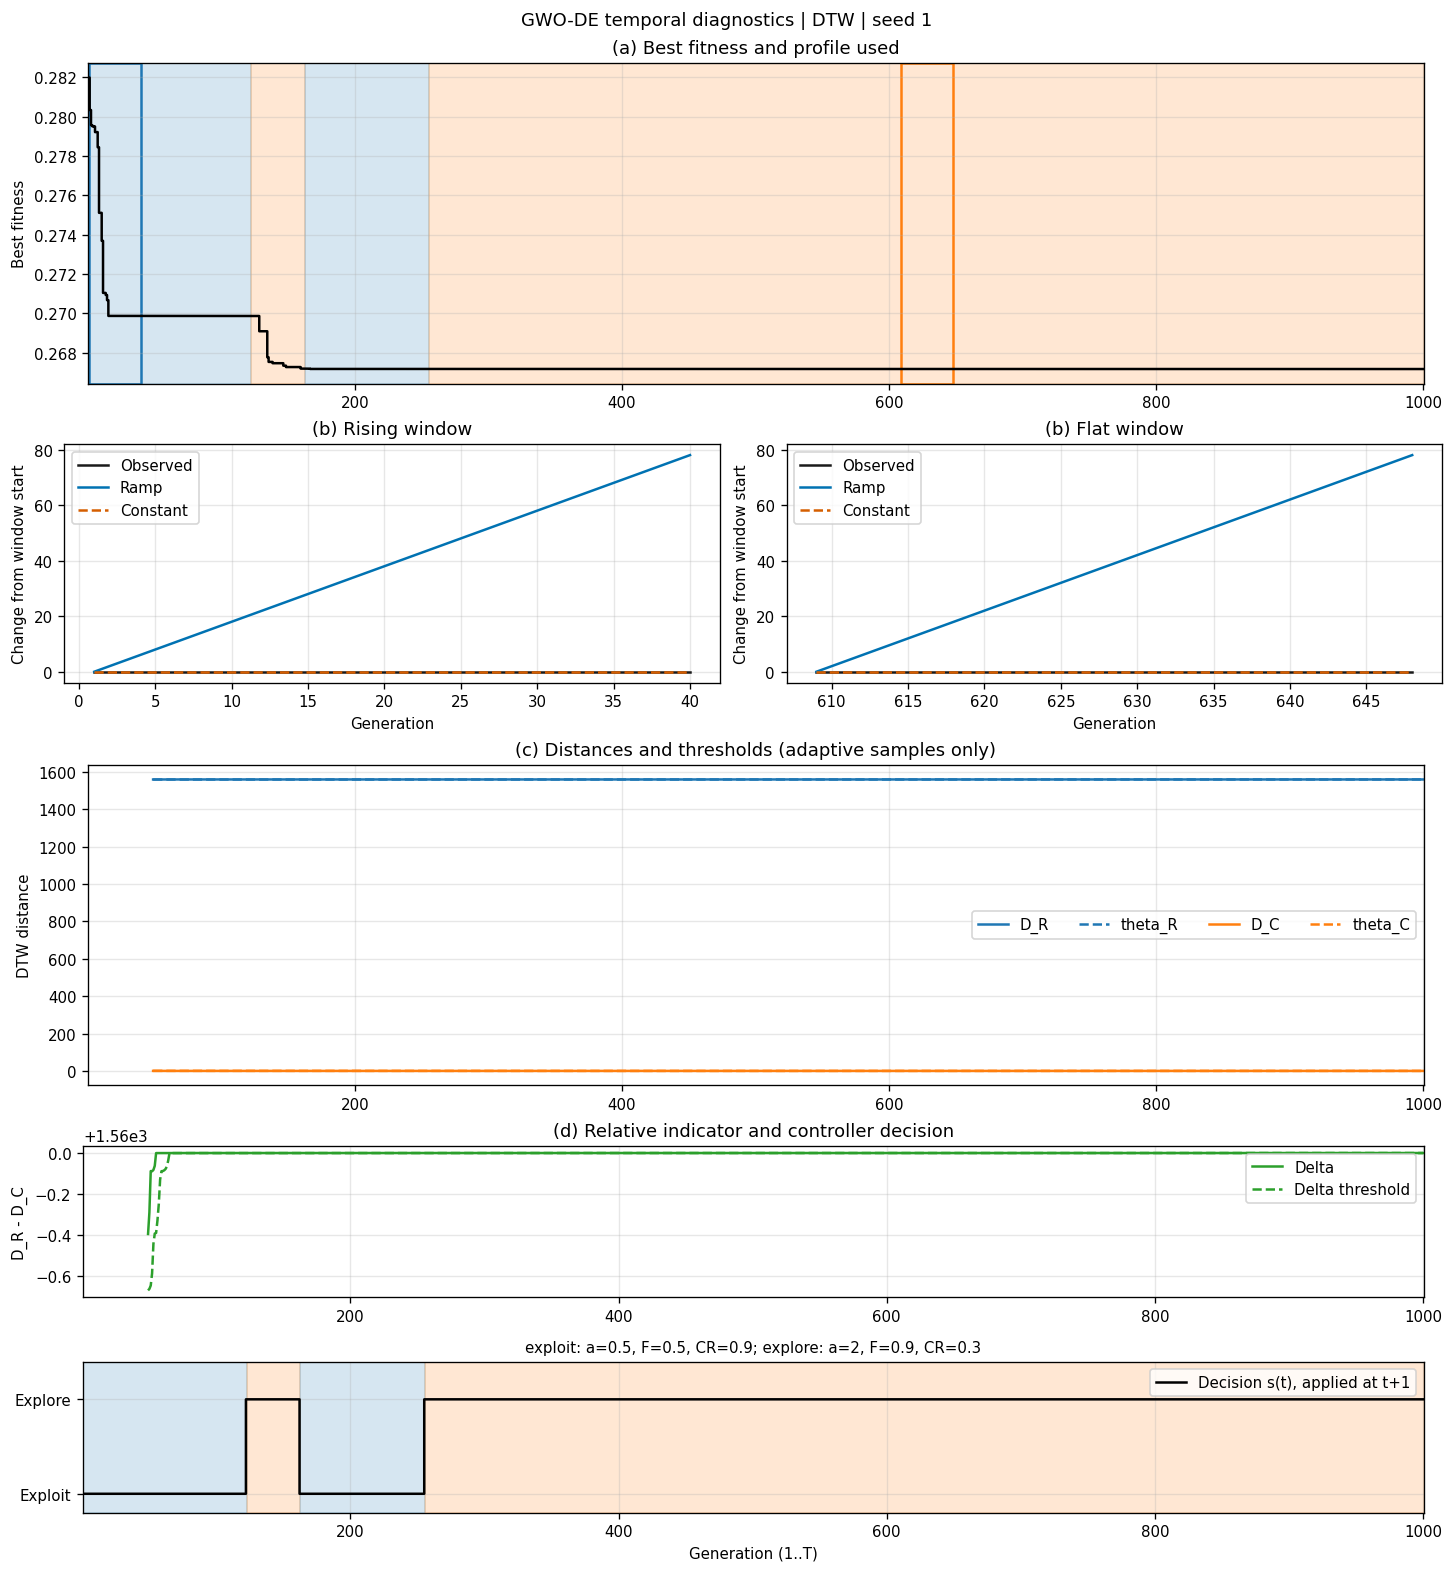

In [19]:
#@title Correr GWO-DE con el monitor sobre HRES2 { display-mode: "form" }
SEMILLA_H = 1  #@param {type:"integer"}
POBLACION_H = 30
GENERACIONES_H = 1000

def _gwo_h(z, lideres, a, rng):
    guiados = np.empty((3, z.shape[0]))
    for k in range(3):
        A = 2.0 * a * rng.random(z.shape[0]) - a
        Cc = 2.0 * rng.random(z.shape[0])
        guiados[k] = lideres[k] - A * np.abs(Cc * lideres[k] - z)
    return np.clip(guiados.mean(axis=0), -1.0, 1.0)

def _de_h(i, z, F_, CR_, rng):
    otros = [j for j in range(z.shape[0]) if j != i]
    r1, r2, r3 = rng.choice(otros, 3, replace=False)
    v = np.clip(z[r1] + F_ * (z[r2] - z[r3]), -1.0, 1.0)
    mascara = rng.random(z.shape[1]) < CR_
    mascara[rng.integers(0, z.shape[1])] = True
    return np.where(mascara, v, z[i])

def hres_dtw(semilla, cfg=CFG_DEFECTO, pob=POBLACION_H, generaciones=GENERACIONES_H, inicio="explotación"):
    # Búsqueda en la caja [-1, 1]^4, que se lleva a los límites del modelo (como gwo_de_hres2/search.py).
    rng = np.random.default_rng(semilla)
    fisico = lambda z: LIM_INF + (z + 1.0) * 0.5 * (LIM_SUP - LIM_INF)
    z = rng.uniform(-1.0, 1.0, (pob, 4))
    obj = np.array([evaluar_lcoe(fisico(fila)) for fila in z])
    mejor_i = int(np.argmin(obj)); mejor, mejor_z = float(obj[mejor_i]), z[mejor_i].copy()
    mon = MonitorDTW(cfg)
    perfil = inicio
    cambios = [(0, perfil)]
    nanW = np.full(cfg.W, np.nan)
    traza = {k: [] for k in ("perfil_usado", "decision", "listo", "adaptativo",
                             "D1", "D2", "delta", "theta_r", "theta_c", "theta_delta", "X", "R", "C")}
    hist = []
    for gen in range(generaciones):
        par = PERFILES[perfil]
        usado = perfil
        lideres = z[np.argsort(obj)[:3]].copy()
        for i in range(pob):
            u_g = _gwo_h(z[i], lideres, par["a"], rng)
            u_d = _de_h(i, z, par["F"], par["CR"], rng)
            f_g, f_d = evaluar_lcoe(fisico(u_g)), evaluar_lcoe(fisico(u_d))
            u, f = (u_g, f_g) if f_g <= f_d else (u_d, f_d)
            if f <= obj[i]:
                z[i], obj[i] = u, f
        i_min = int(np.argmin(obj))
        if obj[i_min] < mejor:
            mejor, mejor_z = float(obj[i_min]), z[i_min].copy()
        hist.append(mejor)

        out = mon.update(-mejor)
        if out["listo"]:
            X = np.array(mon.serie[-cfg.W:], dtype=float)
            R = X[0] + pendiente_rampa(X, cfg) * np.arange(cfg.W)
            Cv = np.full(cfg.W, X[0])
            adaptativo = bool(cfg.adaptativo and len(mon.h_D1) >= 10)
        else:
            X = R = Cv = nanW
            adaptativo = False
        nuevo = siguiente_perfil(perfil, out, cfg)
        if nuevo != perfil:
            perfil = nuevo
            cambios.append((gen, nuevo))
            mon.reiniciar_ventana()
        traza["perfil_usado"].append(usado)
        traza["decision"].append(perfil)
        traza["listo"].append(bool(out["listo"]))
        traza["adaptativo"].append(adaptativo)
        for clave, fuente in (("D1", "D1"), ("D2", "D2"), ("delta", "delta"),
                              ("theta_r", "theta_r"), ("theta_c", "theta_c"), ("theta_delta", "theta_delta")):
            traza[clave].append(out.get(fuente, np.nan))
        traza["X"].append(np.array(X, dtype=float))
        traza["R"].append(np.array(R, dtype=float))
        traza["C"].append(np.array(Cv, dtype=float))
    return np.array(hist), cambios, traza, fisico(mejor_z)

t0 = time.time()
hist_hres, cambios_hres, traza_hres, x_final = hres_dtw(SEMILLA_H)
print(f"Semilla {SEMILLA_H}: LCOE inicial {hist_hres[0]:.4f}, final {hist_hres[-1]:.4f} CNY/kWh  ({time.time()-t0:.0f} s)")
print(f"Cambios de perfil: {len(cambios_hres) - 1}")
print()
print("Vector final de la búsqueda:", np.round(x_final, 2))
mostrar_sistema(x_final)

figura_temporal_diagnostics(hist_hres, traza_hres, CFG_DEFECTO, SEMILLA_H)


### 6c. Las perillas sobre esta curva

Es el mismo gráfico y son las mismas perillas que en el MKP, sobre la curva que acabas de obtener ($y = -\mathrm{LCOE}$). No se vuelve a optimizar.

La diferencia está en la escala. En el MKP el mejor valor sube miles de unidades. Aquí el LCOE cambia en centésimas a lo largo de toda la corrida. Por eso puedes elegir entre la `min_slope` del paper (2.0, en unidades del MKP) y una escalada a esta curva.

**Tu turno:**
1. Compara el sistema de la búsqueda con el tuyo de 6a. ¿Qué fuente domina? ¿Qué batería eligió? ¿Cuánto más barata es su energía?
2. ¿En qué generación se aplana la curva? ¿Coincide con la primera marca del monitor?
3. Cambia `min_slope` entre las dos opciones. ¿Cambian mucho las marcas? Si la curva ya está plana, ¿cuánto importa la pendiente de la rampa?


In [20]:
#@title Sliders sobre la curva de HRES2 { display-mode: "form" }
# Mismas perillas que la sección 4, sobre y = -LCOE de la corrida de 6b. No vuelve a optimizar.
y = -hist_hres
MIN_SLOPE_ESCALADO = float((y.max() - y.min()) / len(y))  # la rampa sube al ritmo medio de mejora de la corrida
print(f"min_slope escalada a esta curva: {MIN_SLOPE_ESCALADO:.3g}")

def _perillas_hres(W=40, band=4, patience=8, min_slope=None):
    if min_slope is None:
        min_slope = MIN_SLOPE_ESCALADO
    guardado = mejor_conocido
    globals()["mejor_conocido"] = None  # la línea del MKP no va en esta curva
    try:
        det = graficar_monitor(y, replace(CFG_DEFECTO, W=int(W), band=int(band), patience=int(patience), min_slope=float(min_slope)))
    finally:
        globals()["mejor_conocido"] = guardado
    print("Detecciones:", det)
    return det

if globals().get("WIDGETS_OK"):
    import ipywidgets as widgets
    from ipywidgets import interact
    interact(_perillas_hres,
             W=widgets.IntSlider(value=40, min=10, max=80, step=5, continuous_update=False),
             band=widgets.IntSlider(value=4, min=1, max=20, continuous_update=False),
             patience=widgets.IntSlider(value=8, min=1, max=15, continuous_update=False),
             min_slope=widgets.Dropdown(
                 options=[("escalada a esta curva", MIN_SLOPE_ESCALADO), ("2.0, la del paper", 2.0)],
                 value=MIN_SLOPE_ESCALADO))


min_slope escalada a esta curva: 1.48e-05


Detecciones: [121, 254, 310, 366, 422, 478, 534, 590, 646, 702, 758, 814, 870, 926, 982]


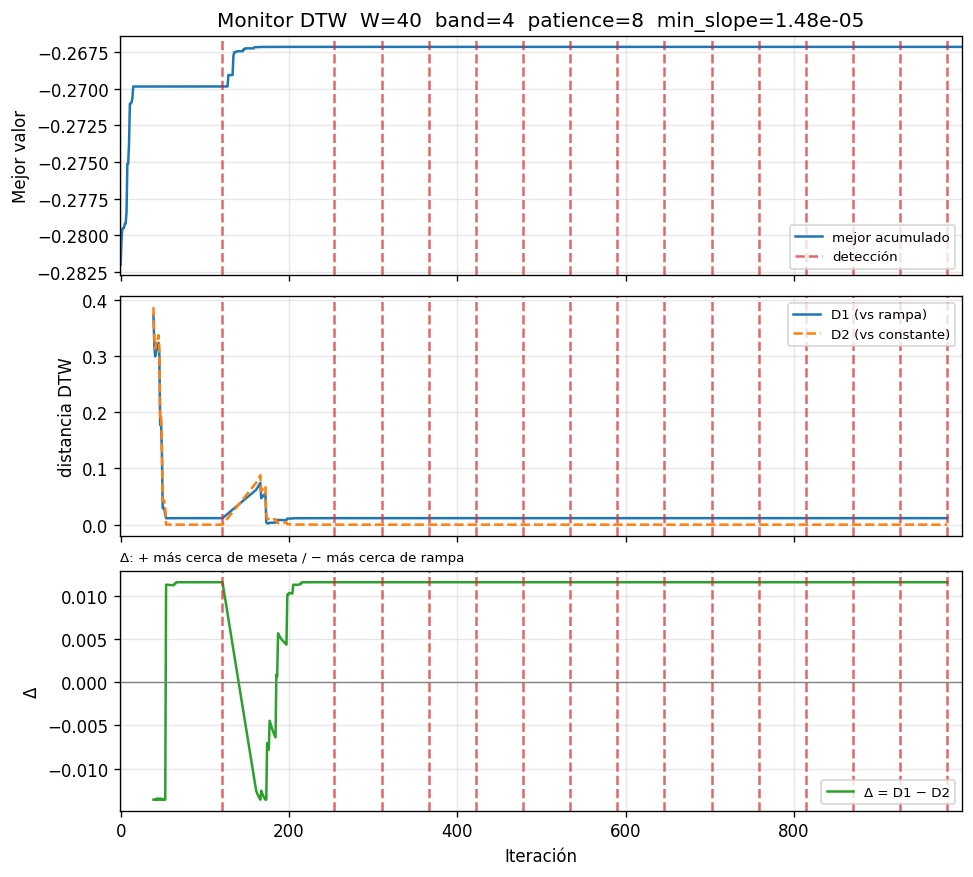

In [21]:
# Sin sliders, cambia los valores y vuelve a ejecutar esta celda.
W_h, band_h, patience_h = 40, 4, 8
min_slope_h = MIN_SLOPE_ESCALADO  # prueba 2.0, la del paper
if not globals().get("WIDGETS_OK"):
    _perillas_hres(W_h, band_h, patience_h, min_slope_h)
else:
    print("Los sliders de arriba ya grafican.")


## 7. Cierre

Para conversar en grupo:

1. ¿El monitor marcó cerca de tu estimación, antes o después?
2. Después de un cambio de perfil, ¿la curva subió? ¿Sabe el monitor si el cambio sirvió?
3. Un mejor acumulado plano no prueba que la población perdió diversidad. ¿Qué medirías?

El paper usa este monitor para cambiar estos perfiles de parámetros en el MKP y en HRES2. Este notebook corre una sola semilla en cada problema: población 20 en el MKP y 30 en HRES2.

Paper: *Time-Series-Driven Parameter Control of a Hybrid Grey Wolf Optimizer and Differential Evolution via Dynamic Time Warping*.

## Referencias

- Sakoe, H., Chiba, S. (1978). Dynamic programming algorithm optimization for spoken word recognition. *IEEE Transactions on Acoustics, Speech, and Signal Processing*, 26(1), 43–49. https://doi.org/10.1109/TASSP.1978.1163055
- Mirjalili, S., Mirjalili, S. M., Lewis, A. (2014). Grey Wolf Optimizer. *Advances in Engineering Software*, 69, 46–61. https://doi.org/10.1016/j.advengsoft.2013.12.007
